# Advanced Data Mining for Data-Driven Insights and Predictive Modeling

## Deliverable 1: Data Collection, Cleaning, and Exploration

## Student Name: Navya Katta

### Step 1: Dataset Introduction and Description

#### Dataset overview

#### Dataset Name: Bank Marketing Dataset
#### Source: UCI Machine Learning Repository
#### Records: 45,211
#### Attributes: 17 (16 input features and one target variable)

The Bank Marketing Dataset contains information about direct marketing campaigns conducted by a Portuguese banking institution. The dataset includes customer demographic information, financial characteristics, previous marketing interactions, and campaign outcomes. The target variable, y, indicates whether a customer subscribed to a term deposit.

#### Justification for Dataset Selection

This dataset was selected because it contains more than 500 records and at least 8–10 attributes, meeting the project requirements. It includes numerical and categorical variables, making it suitable for data preprocessing, exploratory data analysis, classification, clustering, and association rule mining. Its customer and campaign attributes also allow meaningful investigation of factors associated with marketing success.

### Step 2: Import Libraries and Load Dataset

#### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

# Display all columns
pd.set_option("display.max_columns", None)

#### Load Dataset

In [2]:
# Load the Bank Marketing dataset
df = pd.read_csv("bank-full.csv", sep=";")

# Display the first 10 records
df.head(10)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no


#### Check Dataset Dimensions

In [3]:
# Display the number of rows and columns
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 45211
Number of Columns: 17


### Step 3: Data Inspection and Descriptive Statistics

#### Display Column Names

In [4]:
# Display all column names
print("Dataset Columns:")

for column in df.columns:
    print(column)

Dataset Columns:
age
job
marital
education
default
balance
housing
loan
contact
day
month
duration
campaign
pdays
previous
poutcome
y


#### Check DataTypes

In [5]:
# Display dataset structure and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB


#### Descriptive Statistics

In [6]:
# Generate descriptive statistics
df.describe().round(2)

,age,balance,day,duration,campaign,pdays,previous
count,45211.00,45211.00,45211.00,45211.00,45211.00,45211.00,45211.00
mean,40.94,1362.27,15.81,258.16,2.76,40.20,0.58
std,10.62,3044.77,8.32,257.53,3.10,100.13,2.30
min,18.00,-8019.00,1.00,0.00,1.00,-1.00,0.00
25%,33.00,72.00,8.00,103.00,1.00,-1.00,0.00
50%,39.00,448.00,16.00,180.00,2.00,-1.00,0.00
75%,48.00,1428.00,21.00,319.00,3.00,-1.00,0.00
max,95.00,102127.00,31.00,4918.00,63.00,871.00,275.00


#### Categorical Statistics

In [8]:
# Summarize categorical variables
df.describe(include=["object", "str"])

,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211
unique,12,3,4,2,2,2,3,12,4,2
top,blue-collar,married,secondary,no,yes,no,cellular,may,unknown,no
freq,9732,27214,23202,44396,25130,37967,29285,13766,36959,39922


#### Check Missing Values

In [9]:
# Identify missing values
print(df.isnull().sum())

# Calculate total missing values
print("Total Missing Values:", df.isnull().sum().sum())

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64
Total Missing Values: 0


#### Duplicate Records

In [10]:
# Count duplicate rows
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


#### Identify Unknown Values

In [12]:
# Identify categorical columns
categorical_columns = df.select_dtypes(include=["object", "str"]).columns

# Count 'unknown' values in categorical columns
for col in categorical_columns:
    unknown_count = (df[col].astype(str).str.lower() == "unknown").sum()

    if unknown_count > 0:
        print(f"{col}: {unknown_count}")

job: 288
education: 1857
contact: 13020
poutcome: 36959


#### Interpretation

The dataset contains no standard missing values; however, several categorical variables include "unknown" entries. The poutcome column has the highest number of unknown values (36,959), followed by contact (13,020), education (1,857), and job (288). These values represent unavailable or unspecified information and require careful consideration during preprocessing. Rather than removing these records, the unknown categories will initially be retained to preserve information and avoid unnecessary data loss.

### Step 4: Initial Data Quality Checks

#### Target Variable

In [13]:
# Count customers who subscribed and did not subscribe
print(df["y"].value_counts())

# Calculate percentages
print(df["y"].value_counts(normalize=True) * 100)

y
no     39922
yes     5289
Name: count, dtype: int64
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


The target variable is imbalanced, with approximately 88.3% of customers not subscribing to a term deposit.

#### Identify Potential Outliers

In [14]:
# Select numerical columns
numeric_cols = df.select_dtypes(include=np.number).columns

# Calculate potential outliers using IQR
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) | (df[col] > upper)
    ]

    print(f"{col}: {len(outliers)} potential outliers")

age: 487 potential outliers
balance: 4729 potential outliers
day: 0 potential outliers
duration: 3235 potential outliers
campaign: 3064 potential outliers
pdays: 8257 potential outliers
previous: 8257 potential outliers


The IQR method identifies values that fall outside the typical distribution. However, these values are not necessarily errors.

### Step 5: Exploratory Data Analysis

#### Age Distribution of Customers

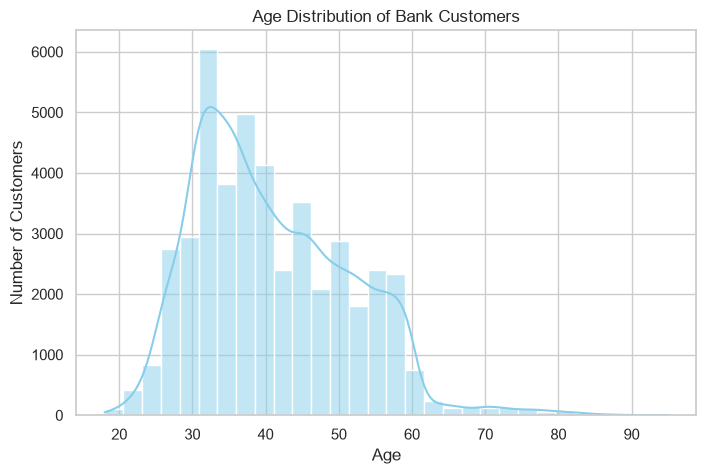

In [15]:
# Visualize age distribution
plt.figure(figsize=(8, 5))

sns.histplot(df["age"], bins=30, kde=True, color="skyblue")

plt.title("Age Distribution of Bank Customers")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()

#### Interpretation

Most customers are concentrated between 30 and 50 years of age, with fewer customers in older age groups. This indicates that middle-aged customers form a substantial portion of the dataset.

#### Term Deposit Subscription Distribution

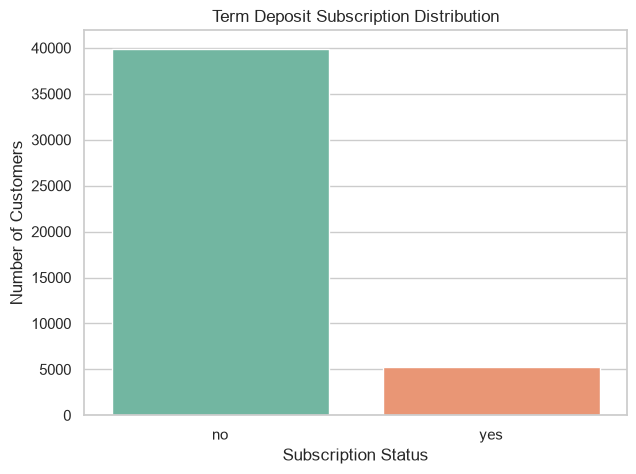

In [16]:
# Visualize subscription distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df,x="y",hue="y",palette="Set2",legend=False)

plt.title("Term Deposit Subscription Distribution")
plt.xlabel("Subscription Status")
plt.ylabel("Number of Customers")
plt.show()

#### Interpretation

Approximately 88.3% of customers did not subscribe to a term deposit, while only 11.7% subscribed. This indicates a significant class imbalance, which should be considered during future classification modeling.

#### Account Balance Distribution and Outliers

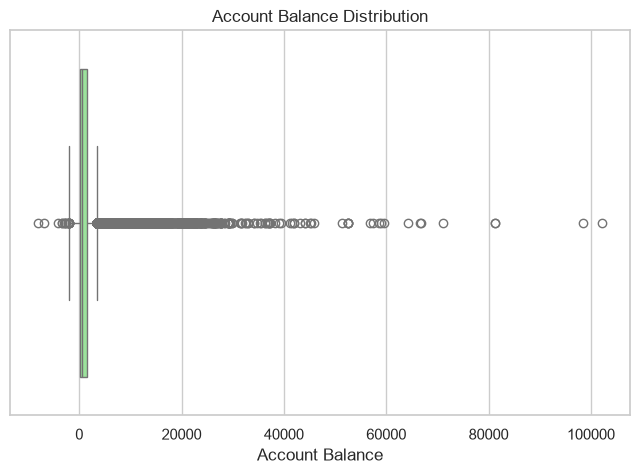

In [17]:
# Identify potential outliers in account balances
plt.figure(figsize=(8, 5))

sns.boxplot(x=df["balance"], color="lightgreen")

plt.title("Account Balance Distribution")
plt.xlabel("Account Balance")
plt.show()

#### Interpretation

The account balance distribution contains several extreme positive values and some negative balances.

#### Correlation Heatmap

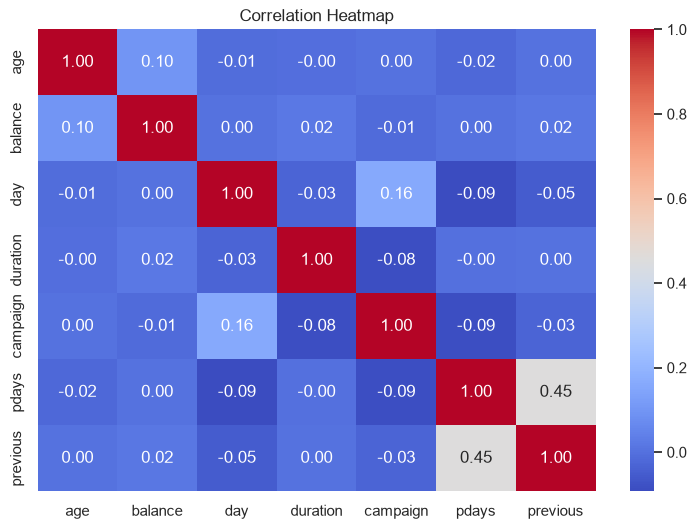

In [18]:
# Examine relationships between numerical features
plt.figure(figsize=(9, 6))

sns.heatmap(df.select_dtypes(include=np.number).corr(),annot=True,cmap="coolwarm",fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

#### Interpretation

The heatmap indicates that most numerical variables have weak linear correlations. The strongest positive correlation is between pdays and previous, suggesting a relationship between previous campaign contact information and the number of earlier contacts.

#### Findings from EDA


The exploratory data analysis revealed that most bank customers are middle-aged, while the subscription outcome is highly imbalanced, with only 11.7% subscribing to term deposits. Account balances contain potential outliers, indicating considerable financial variation among customers. The correlation analysis identified generally weak relationships among numerical variables, although previous campaign-related features showed a moderate association. These findings suggest that future modeling should consider class imbalance, outlier treatment, and appropriate feature selection.